# Chapter 2 — Fundamental Concepts: How Do We Learn?

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 2, explain every theory, and reproduce its code (plus small visual demos).

---

## 1. Chapter Summary

Chapter 2 gives the vocabulary and the mental model used for the entire book.

1. **What is deep learning?** A subset of machine learning that uses neural networks with many layers.
2. **What is machine learning?** A field where a machine *learns* a task from data instead of being explicitly programmed. (Mitchell: a program learns from experience *E* with respect to task *T* and performance measure *P* if its performance at *T*, measured by *P*, improves with *E*.)
3. **Two ways to categorize ML:**
   * **Supervised vs. unsupervised** learning — *do we have the answers (labels)?*
   * **Parametric vs. non-parametric** models — *is the knowledge stored in a fixed number of parameters or in the data itself?*
4. **Supervised learning** maps *what you know* → *what you want to know* (e.g. pixels → "cat").
5. **Unsupervised learning** groups or clusters data without being told the answer (e.g. k-means).
6. **Parametric models** (e.g. linear regression, neural networks) have a **fixed** number of knobs that are *tuned*. **Non-parametric models** (e.g. k-NN) have a number of "knobs" that *grows with the data*.
7. The core loop of nearly all supervised learning in this book: **Predict → Compare → Learn.**

---

## 2. Theory Deep-Dive

### 2.1 Supervised learning
Given pairs $(x_i, y_i)$, learn a function $f$ such that $f(x_i) \approx y_i$ and, crucially, $f(x_{new})$ is good on *unseen* data.
* *Regression*: $y$ is a number (temperature, price).
* *Classification*: $y$ is a category (cat / dog, digit 0-9).

The network transforms a **dataset you know** into a **dataset you want to know**.

### 2.2 Unsupervised learning
Only $x_i$ is given. The algorithm finds structure on its own — typically **clustering** (grouping similar points). Deep learning also uses it to learn *representations* (e.g. embeddings in Chapter 11).

### 2.3 Parametric vs. non-parametric

| | Parametric | Non-parametric |
|---|---|---|
| Knowledge lives in | a **fixed set of parameters** (weights) | the **training data itself** |
| # parameters | fixed, independent of data size | grows with the data |
| Training | adjust parameters (search/optimize) | essentially "count" or store |
| Prediction cost | cheap (just evaluate the function) | can be expensive (look at data) |
| Examples | linear regression, neural nets | k-NN, kernel methods |

> Book analogy: a parametric model is a machine with **knobs** that you turn until it works; a non-parametric model is a machine that **counts / remembers** things. Deep learning is (mostly) *supervised parametric* learning.

### 2.4 The Predict → Compare → Learn paradigm
1. **Predict** — run the input through the model: `pred = input * weight`.
2. **Compare** — measure how wrong it is: `error = (pred - goal) ** 2`.
3. **Learn** — decide how to change the weight to make the error smaller, and update it.

Repeat until the error is (close to) zero. Squaring the error makes it always positive and punishes large mistakes more.

---

## 3. Code Reproduction

### 3.1 Parametric vs non-parametric (linear model vs. k-NN)

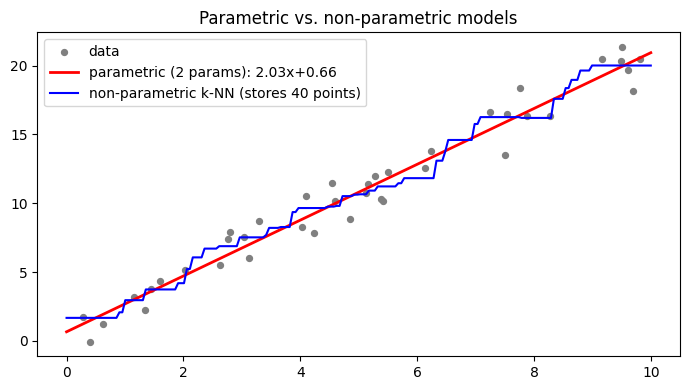

Parametric model size     : 2 numbers (constant as data grows)
Non-parametric model size : 80 numbers (grows with data)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("folder-picture", exist_ok=True)

rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 10, 40))
y = 2 * x + 1 + rng.normal(0, 1.5, size=x.shape)       # noisy line

# ---- Parametric: linear model with exactly 2 parameters (w, b) -------------
A = np.c_[x, np.ones_like(x)]
w, b = np.linalg.lstsq(A, y, rcond=None)[0]

# ---- Non-parametric: k-NN regression, the "model" is the whole dataset -----
def knn_predict(x_query, k=5):
    d = np.abs(x[None, :] - x_query[:, None])
    idx = np.argsort(d, axis=1)[:, :k]
    return y[idx].mean(axis=1)

xs = np.linspace(0, 10, 200)
plt.figure(figsize=(7, 4))
plt.scatter(x, y, c="gray", s=18, label="data")
plt.plot(xs, w * xs + b, "r", lw=2, label=f"parametric (2 params): {w:.2f}x+{b:.2f}")
plt.plot(xs, knn_predict(xs), "b", lw=1.5, label=f"non-parametric k-NN (stores {len(x)} points)")
plt.legend(); plt.title("Parametric vs. non-parametric models")
plt.tight_layout()
plt.savefig("folder-picture/ch02_parametric_vs_nonparametric.png", dpi=120, bbox_inches="tight")
plt.show()
print("Parametric model size     :", 2, "numbers (constant as data grows)")
print("Non-parametric model size :", 2 * len(x), "numbers (grows with data)")

### 3.2 Supervised vs. unsupervised

* **Supervised** (labels given): a nearest-centroid classifier learns from labelled points.
* **Unsupervised** (no labels): k-means has to *discover* the two groups by itself.

Supervised accuracy: 1.0
Unsupervised cluster agreement with hidden truth: 1.0


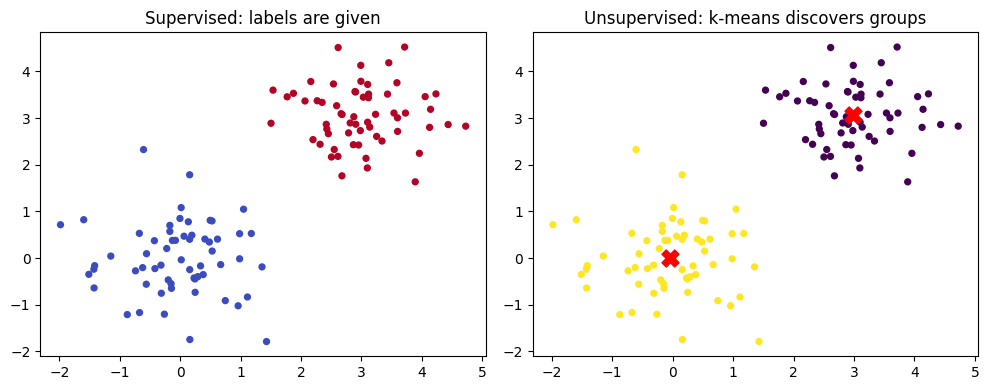

In [2]:
rng = np.random.default_rng(3)
g1 = rng.normal([0, 0], 0.7, size=(60, 2))
g2 = rng.normal([3, 3], 0.7, size=(60, 2))
X = np.vstack([g1, g2])
labels = np.r_[np.zeros(60), np.ones(60)]

# --- supervised: use labels to compute class centroids ---
cent_sup = np.array([X[labels == k].mean(axis=0) for k in (0, 1)])
pred_sup = np.argmin(((X[:, None] - cent_sup[None]) ** 2).sum(-1), axis=1)
print("Supervised accuracy:", (pred_sup == labels).mean())

# --- unsupervised: k-means, labels are never used ---
def kmeans(X, k=2, iters=20, seed=0):
    r = np.random.default_rng(seed)
    cent = X[r.choice(len(X), k, replace=False)]
    for _ in range(iters):
        assign = np.argmin(((X[:, None] - cent[None]) ** 2).sum(-1), axis=1)
        cent = np.array([X[assign == j].mean(axis=0) for j in range(k)])
    return assign, cent

assign, cent_unsup = kmeans(X)
agree = max((assign == labels).mean(), (assign != labels).mean())   # cluster ids are arbitrary
print("Unsupervised cluster agreement with hidden truth:", agree)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(*X.T, c=labels, cmap="coolwarm", s=18); ax[0].set_title("Supervised: labels are given")
ax[1].scatter(*X.T, c=assign, cmap="viridis", s=18)
ax[1].scatter(*cent_unsup.T, c="red", marker="X", s=150)
ax[1].set_title("Unsupervised: k-means discovers groups")
plt.tight_layout()
plt.savefig("folder-picture/ch02_supervised_vs_unsupervised.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.3 Predict → Compare → Learn (the book's first "learning" loop)

Single input, single weight. We want `input * weight` to equal `goal_prediction`.

* `input = 0.5`, `goal_prediction = 0.8`, initial `weight = 0.5`
* error = `(pred - goal)²`
* update: `weight -= (pred - goal) * input`   (the "pure error × input" rule — derived properly in Chapters 4–5)

iter  0  Error: 0.302500  Prediction: 0.250000
iter  1  Error: 0.170156  Prediction: 0.387500
iter  2  Error: 0.095713  Prediction: 0.490625
iter  3  Error: 0.053839  Prediction: 0.567969
iter  4  Error: 0.030284  Prediction: 0.625977
iter 19  Error: 0.000005  Prediction: 0.797674


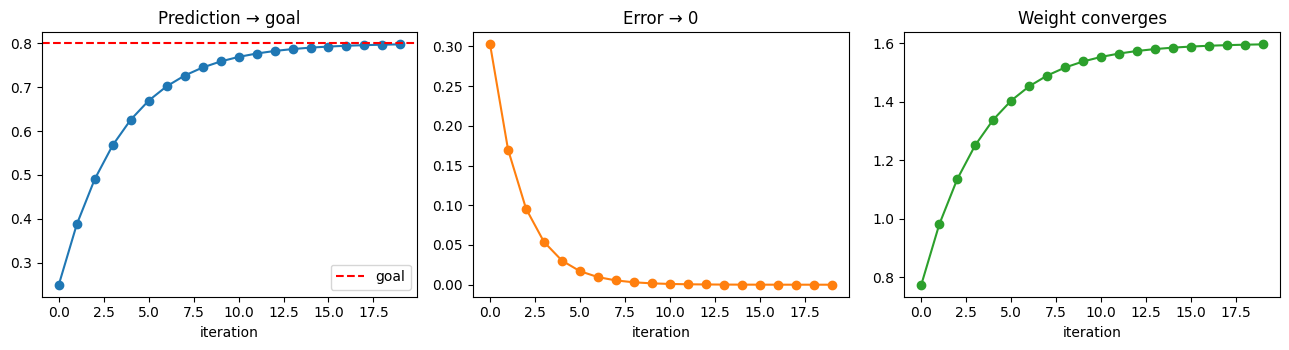

In [3]:
weight = 0.5
input_ = 0.5
goal_prediction = 0.8

preds, errors, weights = [], [], []
for i in range(20):
    pred = input_ * weight                                 # PREDICT
    error = (pred - goal_prediction) ** 2                  # COMPARE
    delta = pred - goal_prediction
    weight_delta = delta * input_
    weight = weight - weight_delta                         # LEARN
    preds.append(pred); errors.append(error); weights.append(weight)
    if i < 5 or i == 19:
        print(f"iter {i:2d}  Error: {error:.6f}  Prediction: {pred:.6f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(preds, "o-"); ax[0].axhline(goal_prediction, color="r", ls="--", label="goal")
ax[0].set_title("Prediction → goal"); ax[0].set_xlabel("iteration"); ax[0].legend()
ax[1].plot(errors, "o-", color="tab:orange"); ax[1].set_title("Error → 0"); ax[1].set_xlabel("iteration")
ax[2].plot(weights, "o-", color="tab:green"); ax[2].set_title("Weight converges"); ax[2].set_xlabel("iteration")
plt.tight_layout()
plt.savefig("folder-picture/ch02_predict_compare_learn.png", dpi=120, bbox_inches="tight")
plt.show()

**Reading the output:** the error falls geometrically (each step multiplies it by a constant < 1) and the prediction creeps towards `0.8`. This is the simplest possible instance of *learning*: a number (`weight`) was adjusted automatically using the error signal.

---

## 4. Key Takeaways

* ML = learn from data; DL = ML with deep neural networks.
* **Supervised** needs labels; **unsupervised** finds structure without them.
* **Parametric** models keep knowledge in a fixed set of tunable weights (neural networks); **non-parametric** ones keep/count the data.
* Everything in the book rests on **Predict → Compare → Learn**.

➡️ **Next:** Chapter 3 — how a neural network makes predictions (the *predict* step) with several inputs and outputs.